# 02 — Data Cleaning : contrôle qualité du dataset CarDD

**Règles de cette phase**
- Le dataset original n'est **jamais modifié ni déplacé** : toutes les fonctions sont en lecture seule.
- Rien n'est supprimé automatiquement : chaque contrôle produit une **liste de problèmes**, puis une **politique de nettoyage** explicite produit des **tables de décisions** (`reports/cleaning/`).
- Le code des contrôles est dans `src/data/cleaning.py` (testé dans `tests/test_cleaning.py`).

Durée d'exécution complète : environ 5 minutes (chaque image est décodée entièrement, puis les quasi-doublons sont vérifiés).

In [1]:
import sys, time
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.coco_loader import load_all_splits, add_bbox_features, image_dir, SPLITS
from src.data.image_io import read_image_rgb
from src.data import cleaning as cl

pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
CLASS_ORDER = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
REPORT_DIR = PROJECT_ROOT / "reports" / "cleaning"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

images, annotations, categories = load_all_splits()
annotations = add_bbox_features(annotations, images)
print(f"{len(images)} images, {len(annotations)} annotations, {len(categories)} catégories")

4000 images, 8740 annotations, 6 catégories


## 1. Champs obligatoires manquants ou nuls

In [2]:
required = cl.check_required_fields(images, annotations)
required

,table,field,n_problems,detail
0,image,id,0,valeurs nulles/vides
1,image,file_name,0,valeurs nulles/vides
2,image,width,0,valeurs nulles/vides
3,image,height,0,valeurs nulles/vides
4,annotation,id,0,valeurs nulles/vides
5,annotation,image_id,0,valeurs nulles/vides
6,annotation,category_id,0,valeurs nulles/vides
7,annotation,bbox_x,0,valeurs nulles/vides
8,annotation,bbox_y,0,valeurs nulles/vides
9,annotation,bbox_w,0,valeurs nulles/vides


**Interprétation.** Pour les images (`id`, `file_name`, `width`, `height`) comme pour les annotations (`id`, `image_id`, `category_id`, bbox, `segmentation`, `area`),
la colonne `n_problems` indique le nombre de valeurs absentes, nulles ou vides. Une valeur de 0 partout signifie qu'aucun enregistrement n'est incomplet.

## 2. Identifiants COCO, catégories inconnues, orphelins

In [3]:
ids = cl.check_coco_ids(images, annotations)
unknown = cl.check_unknown_categories(annotations, categories)
orphans = cl.check_orphans(images, annotations)
for name, df in [("identifiants incohérents", ids), ("catégories inconnues", unknown), ("orphelins", orphans)]:
    print(f"{name:26s}: {len(df)} problème(s)", df["check"].value_counts().to_dict() if len(df) else "")

identifiants incohérents  : 0 problème(s) 
catégories inconnues      : 0 problème(s) 
orphelins                 : 0 problème(s) 


**Interprétation.** On vérifie : ids d'image et d'annotation uniques, `file_name` référencé une seule fois, dimensions positives,
`category_id` appartenant aux 6 catégories, annotations pointant vers une image existante et images possédant au moins une annotation.
Aucun problème n'est détecté : la structure COCO est cohérente.

## 3. Fichiers introuvables ou non référencés

In [4]:
files = cl.check_files_on_disk(images)
print(f"{len(files)} problème(s)", files["check"].value_counts().to_dict() if len(files) else "")

0 problème(s) 


**Interprétation.** Chaque image citée dans les JSON existe sur disque, et aucun fichier `.jpg` présent dans les dossiers n'est absent des JSON.

## 4. Fichiers corrompus et dimensions réelles

Chaque image est **décodée entièrement** deux fois (Pillow, qui détecte les JPEG tronqués, puis OpenCV, la bibliothèque utilisée ensuite).
On en profite pour calculer l'empreinte **SHA-256** (doublons exacts) ainsi que le **pHash** et le **dHash** (indices de ressemblance visuelle).

In [5]:
t0 = time.time()
scan = cl.scan_image_files(images)
corrupt = cl.check_corrupt_images(scan, images)
print(f"Scan de {len(scan)} images en {time.time() - t0:.0f} s")
print(f"Images lisibles : {scan['readable'].sum()} / {len(scan)}")
print(f"{len(corrupt)} problème(s)", corrupt["check"].value_counts().to_dict() if len(corrupt) else "")

Scan de 4000 images en 103 s
Images lisibles : 4000 / 4000
0 problème(s) 


**Interprétation.** Toutes les images se décodent sans erreur avec les deux bibliothèques, et leurs dimensions réelles sont identiques à celles des JSON.
Aucun fichier corrompu.

## 5. Annotations vides et bounding boxes invalides

In [6]:
ann_issues = cl.check_annotations(annotations)
all_checks = ["bbox_dimension_nulle", "bbox_hors_image", "segmentation_vide", "polygone_invalide",
              "bbox_incohérente_polygone", "area_supérieure_bbox", "bbox_minuscule", "annotation_dupliquée"]
ann_issues["check"].value_counts().reindex(all_checks, fill_value=0).rename("n_annotations").to_frame()

,n_annotations
check,
bbox_dimension_nulle,0
bbox_hors_image,0
segmentation_vide,0
polygone_invalide,0
bbox_incohérente_polygone,0
area_supérieure_bbox,0
bbox_minuscule,96
annotation_dupliquée,0


**Interprétation.** Aucune bbox de taille nulle, aucune bbox sortant de l'image, aucun polygone vide ou invalide, aucune incohérence entre bbox et polygone,
aucune `area` impossible, aucune annotation dupliquée. **Le seul signal concerne 96 bbox « minuscules »** (un côté < 16 px). Regardons-les.

Par classe : {'crack': 76, 'dent': 11, 'scratch': 9}
Les deux côtés < 16 px : 2  |  un côté < 8 px : 9


,count,mean,std,min,25%,50%,75%,max
bbox_w,96.0,29.7,31.3,7.5,13.1,14.9,29.5,159.6
bbox_h,96.0,34.9,24.8,7.4,14.2,29.8,49.4,100.6


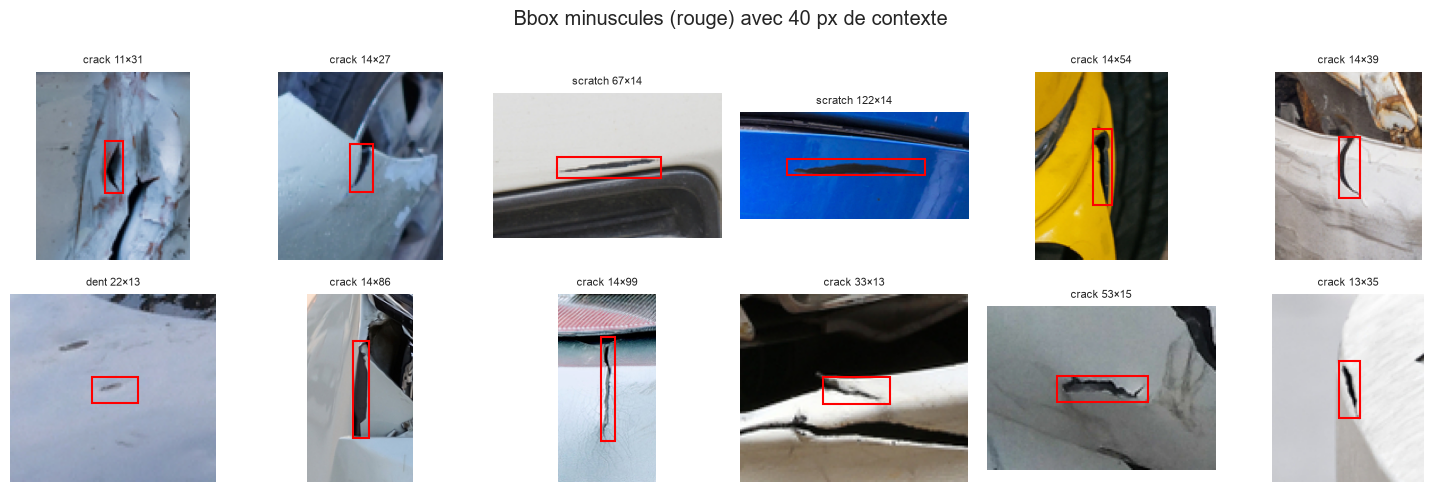

In [7]:
tiny = annotations[(annotations["bbox_w"] < 16) | (annotations["bbox_h"] < 16)]
print("Par classe :", tiny["category_name"].value_counts().to_dict())
print(f"Les deux côtés < 16 px : {((tiny['bbox_w'] < 16) & (tiny['bbox_h'] < 16)).sum()}  |  un côté < 8 px : {((tiny['bbox_w'] < 8) | (tiny['bbox_h'] < 8)).sum()}")
display(tiny[["bbox_w", "bbox_h"]].describe().round(1).T)

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
img_index = images.set_index(["split", "id"])
for ax, a in zip(axes.ravel(), tiny.sample(12, random_state=1).itertuples()):
    r = img_index.loc[(a.split, a.image_id)]
    img = read_image_rgb(image_dir(a.split) / r["file_name"])
    m = 40  # marge de contexte pour voir où se trouve la région
    x0, y0 = max(0, int(a.bbox_x) - m), max(0, int(a.bbox_y) - m)
    crop = img[y0:int(a.bbox_y + a.bbox_h) + m, x0:int(a.bbox_x + a.bbox_w) + m]
    ax.imshow(crop); ax.add_patch(plt.Rectangle((a.bbox_x - x0, a.bbox_y - y0), a.bbox_w, a.bbox_h, fill=False, ec="red", lw=1.5))
    ax.set_title(f"{a.category_name} {a.bbox_w:.0f}×{a.bbox_h:.0f}", fontsize=8); ax.axis("off")
plt.suptitle("Bbox minuscules (rouge) avec 40 px de contexte"); plt.tight_layout(); plt.show()

**Interprétation.** Ces petites boîtes sont surtout des **fissures fines et allongées** (*crack*, ≈ 80 % des cas) : un côté est petit mais l'autre est long.
Seules 2 boîtes sont petites dans les deux dimensions. Ce sont de **vraies annotations**, pas des erreurs.
Les supprimer retirerait environ 8 % des exemples de *crack*, une classe déjà minoritaire.
**Décision : conserver et signaler** ; en phase 3 on ajoutera une **marge de contexte** autour de la boîte avant de la redimensionner.

## 6. Doublons exacts (contenu binaire identique)

In [8]:
exact = cl.find_exact_duplicates(scan)
print(f"Paires d'images strictement identiques (même SHA-256) : {len(exact)}")
exact

Paires d'images strictement identiques (même SHA-256) : 0


,split_a,id_a,file_a,split_b,id_b,file_b,hamming,kind,cross_split


**Interprétation.** Aucun fichier n'est une copie binaire d'un autre, ni dans un split ni entre splits.

## 7. Quasi-doublons (même photo retouchée, ou même scène)

Un doublon exact est facile à trouver, mais une **même photo légèrement modifiée** (recolorée, éclaircie, retournée en miroir, recadrée) a une empreinte SHA-256 différente.
Si une telle copie se trouve dans le train **et** dans la validation ou le test, le modèle sera évalué sur une image qu'il a pratiquement déjà vue : c'est une **fuite de données**, qui gonfle artificiellement les scores.

**Méthode en deux étapes (vision classique, sans Deep Learning) :**
1. **Candidats** (rapide, sur les ≈ 8 millions de paires) : pHash ou dHash proche, **ou** miniatures 32×32 corrélées (niveaux de gris et contours Sobel), **ou** meilleur voisin en miroir.
2. **Vérification** (précise, sur les candidats seulement) : points clés **ORB** + **RANSAC**. On compte les correspondances de points cohérentes avec une même transformation géométrique (*inliers*).
   Deux photos de la même scène en partagent des dizaines ou des centaines ; deux photos différentes en ont presque toujours moins de 10.

Le seuil (`min_inliers = 25`) a été choisi en examinant visuellement des paires de part et d'autre : voir les galeries plus bas.

8357 paires candidates vérifiées en 147 s ; origine : {'miniatures': 4114, 'miroir': 3458, 'dhash': 744, 'phash': 41}


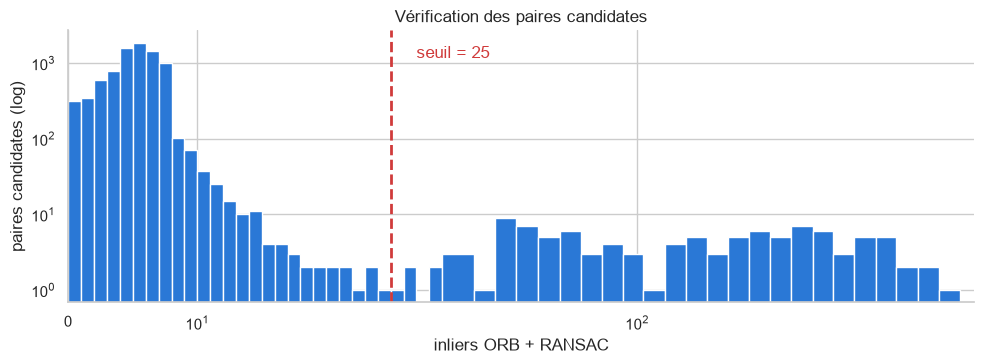

inliers
0-5                       5510
6-10                      2657
11-24                       84
25-99 (même scène)          45
≥100 (copie retouchée)      61
Name: count, dtype: int64


In [9]:
t0 = time.time()
thumbs = cl.compute_thumbnails(images)
cand = cl.candidate_pairs(images, thumbs, scan)
pairs = cl.find_near_duplicates(images, cand, min_inliers=25)
print(f"{len(cand)} paires candidates vérifiées en {time.time() - t0:.0f} s ; origine :", cand["source"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.unique(np.r_[0:30:1, np.logspace(np.log10(30), np.log10(pairs["inliers"].max() + 1), 25).astype(int)])
ax.hist(pairs["inliers"], bins=bins, color="#2a78d6", edgecolor="white")
ax.axvline(25, color="#d03b3b", lw=2, ls="--"); ax.text(27, ax.get_ylim()[1] * 0.6, "seuil = 25", color="#d03b3b")
ax.set_xscale("symlog", linthresh=30); ax.set_yscale("log"); ax.set_xlim(0, pairs["inliers"].max() * 1.1)
ax.set_xlabel("inliers ORB + RANSAC"); ax.set_ylabel("paires candidates (log)")
ax.set_title("Vérification des paires candidates"); plt.tight_layout(); plt.show()
print(pd.cut(pairs["inliers"], [-1, 5, 10, 24, 99, 10_000],
             labels=["0-5", "6-10", "11-24", "25-99 (même scène)", "≥100 (copie retouchée)"]).value_counts().sort_index())

**Interprétation.** L'immense majorité des candidats a très peu d'inliers (< 10) : ce sont des photos différentes qui se ressemblaient seulement en miniature.
Une petite population se détache nettement au-delà de 25, avec un plateau entre 100 et plus de 800 inliers : ce sont des copies d'une même photo.

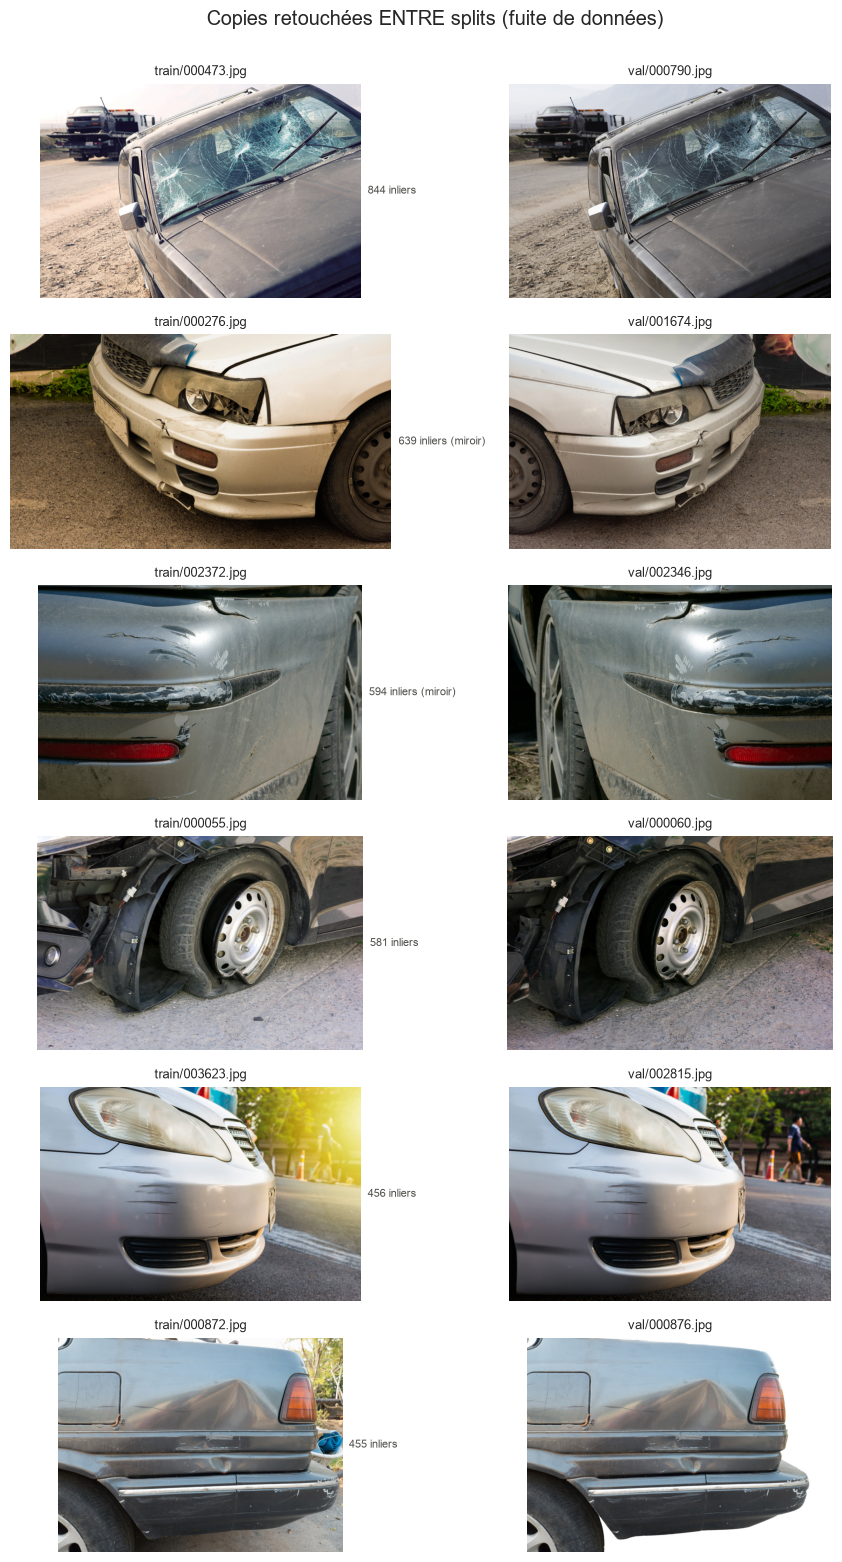

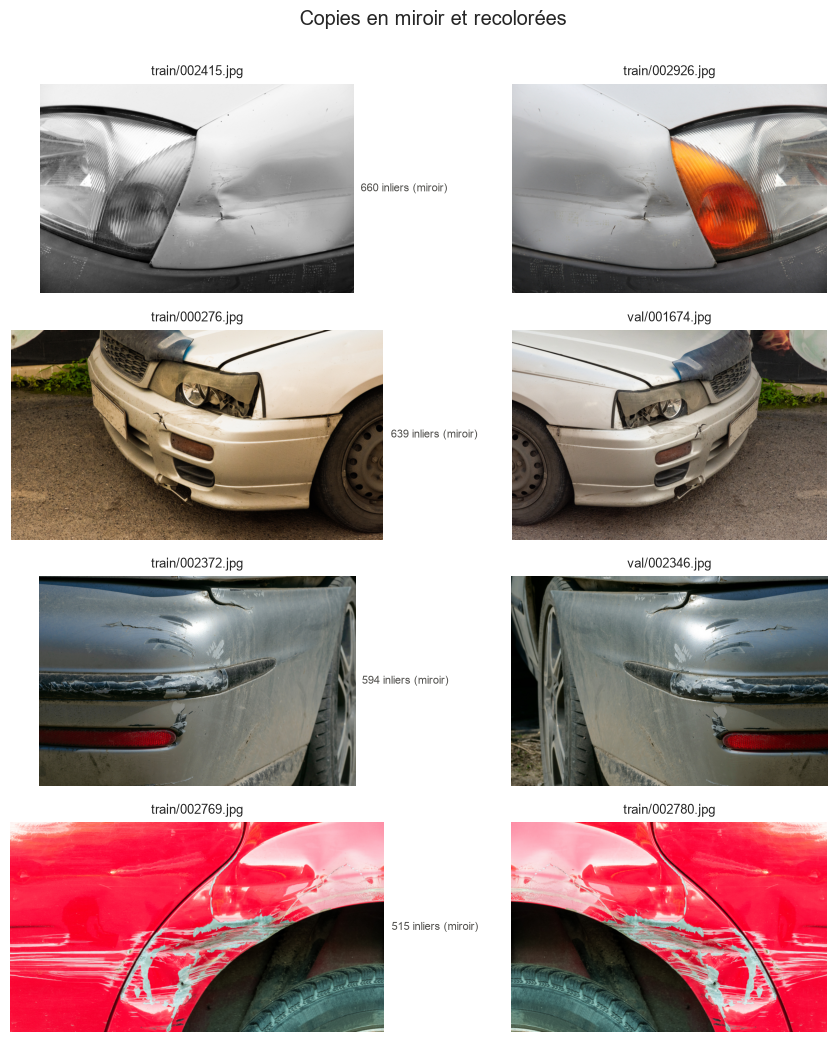

In [10]:
def show_pairs(df, title, n=8):
    df = df.head(n)
    fig, axes = plt.subplots(len(df), 2, figsize=(9, 2.6 * len(df)))
    axes = np.atleast_2d(axes)
    for k, r in enumerate(df.itertuples()):
        for j, (s, f) in enumerate([(r.split_a, r.file_a), (r.split_b, r.file_b)]):
            axes[k, j].imshow(read_image_rgb(image_dir(s) / f)); axes[k, j].axis("off")
            axes[k, j].set_title(f"{s}/{f}", fontsize=9)
        axes[k, 0].text(1.02, 0.5, f"{r.inliers} inliers{' (miroir)' if r.flip else ''}", transform=axes[k, 0].transAxes,
                        fontsize=8, va="center", color="#52514e")
    plt.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

dups = pairs[pairs["is_duplicate"]]
show_pairs(dups[dups["cross_split"]].sort_values("inliers", ascending=False), "Copies retouchées ENTRE splits (fuite de données)", 6)
show_pairs(dups[dups["flip"]].sort_values("inliers", ascending=False), "Copies en miroir et recolorées", 4)

**Interprétation.** Il s'agit bien de la **même photographie** modifiée : variation de luminosité ou de teinte, carrosserie recolorée, image retournée en miroir.
Ces variantes semblent faire partie du dataset d'origine. Plusieurs d'entre elles sont réparties **entre train, validation et test**.

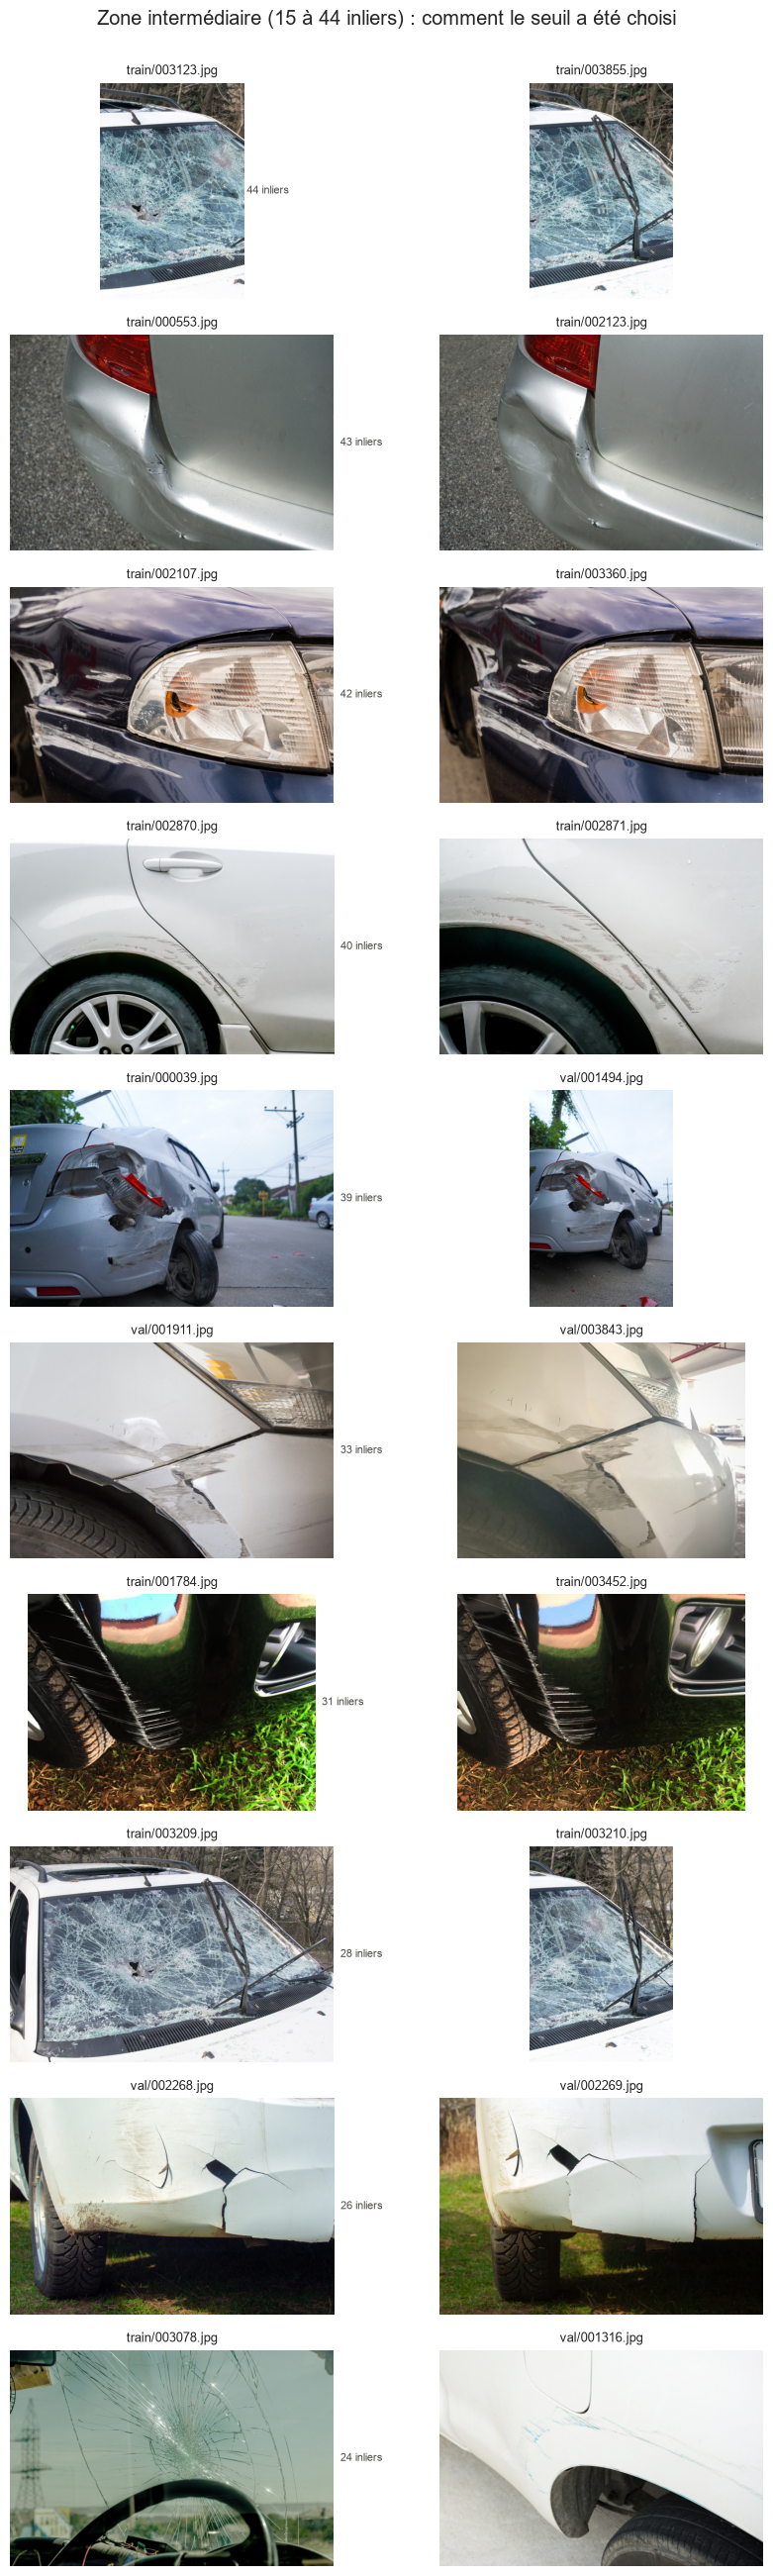

In [11]:
grey = pairs[(pairs["inliers"] >= 15) & (pairs["inliers"] < 45)].sort_values("inliers", ascending=False)
show_pairs(grey.iloc[::2], "Zone intermédiaire (15 à 44 inliers) : comment le seuil a été choisi", 10)

**Interprétation de la zone intermédiaire.** Entre 25 et 100 inliers, on trouve surtout la **même voiture et le même dommage photographiés deux fois**
(prises en rafale, recadrage plus serré). Ce n'est pas une copie au sens strict, mais c'est **la même information** : il faut la traiter comme un doublon potentiel.
On y observe aussi **quelques faux positifs** (photos différentes mais à la géométrie similaire). Sous 25 inliers, les paires sont très majoritairement différentes.
Le seuil de 25 est donc un compromis assumé : il peut exclure à tort quelques images de l'évaluation, ce qui est préférable à laisser passer une fuite.

In [12]:
groups = cl.duplicate_groups(pairs)
print(f"Paires de doublons : {len(dups)} (dont {dups['cross_split'].sum()} entre splits ; "
      f"{(dups['inliers'] >= cl.STRONG_COPY_INLIERS).sum()} copies retouchées ≥ {cl.STRONG_COPY_INLIERS} inliers, "
      f"{(dups['inliers'] < cl.STRONG_COPY_INLIERS).sum()} même scène)")
print(f"Images concernées : {len(groups)} réparties en {groups['group'].nunique()} groupes")
print("\nSplits présents dans chaque groupe :")
print(groups.drop_duplicates("group")["group_splits"].value_counts().to_string())
print("\nPaires par combinaison de splits :")
print(dups.groupby(["split_a", "split_b"]).size().to_string())

Paires de doublons : 106 (dont 40 entre splits ; 61 copies retouchées ≥ 100 inliers, 45 même scène)
Images concernées : 186 réparties en 87 groupes

Splits présents dans chaque groupe :
group_splits
train             43
train+val         26
test+train         8
val                8
test+train+val     1
test+val           1

Paires par combinaison de splits :
split_a  split_b
train    test        9
         train      57
         val        29
val      test        2
         val         9


**Interprétation.** Les doublons concernent un petit nombre d'images (moins de 5 % du dataset), mais **plus d'un tiers des groupes traverse la frontière entre splits**
(train+val, train+test, …). C'est précisément ce que le cahier des charges demandait de vérifier : sans traitement, une partie des images de validation et de test
serait des copies d'images d'entraînement.

## 8. Politique de nettoyage

| Problème | Constat | Décision | Justification |
|---|---|---|---|
| Champs manquants, ids incohérents, catégories inconnues, orphelins | aucun | rien à faire | — |
| Fichiers introuvables ou corrompus | aucun | rien à faire | — |
| Bbox nulles, hors image, polygones invalides, doublons d'annotation | aucun | *si présents* : exclusion (bbox hors image : recadrage) | règle prête pour d'autres versions du dataset |
| Bbox minuscules (un côté < 16 px) | 96, surtout des *crack* allongés | **conservées et signalées** | vraies annotations ; marge de contexte en phase 3 |
| Doublons exacts | aucun | rien à faire | — |
| Quasi-doublons **dans le train** | variantes recolorées, en miroir, rafales | **conservés** | même effet qu'une augmentation de données ; ne biaise pas l'évaluation |
| Quasi-doublons **val/test ↔ train** (ou test ↔ val) | présents | **exclus de l'évaluation « propre »** ; splits officiels inchangés | supprime la fuite de données ; priorité train > val > test |
| Copies **à l'intérieur** de val ou test | présentes | une seule copie gardée pour l'évaluation propre | évite de compter deux fois la même photo |

**Concrètement**, rien n'est effacé. Deux tables de décisions sont produites :
- `image_decisions.csv` : pour chaque image, `eval_keep` et la raison d'une éventuelle exclusion ;
- `annotation_decisions.csv` : pour chaque annotation, `keep`, les `flags` de qualité et `image_eval_keep`.

En phase 5, nous rapporterons les scores sur le **test officiel** (comparables à la littérature) **et** sur le **test propre** (sans fuite).
La validation propre servira à choisir les hyperparamètres.

In [13]:
image_dec, ann_dec = cl.apply_cleaning_policy(images, groups, ann_issues, annotations)
print("Images exclues de l'évaluation propre, par raison :")
print(image_dec.loc[~image_dec["eval_keep"], "reason"].value_counts().to_string())
print("\nAnnotations exclues (invalides) :", (~ann_dec["keep"]).sum())
print("Annotations signalées :", ann_dec.loc[ann_dec["flags"] != "", "flags"].value_counts().to_dict())

Images exclues de l'évaluation propre, par raison :
reason
quasi-doublon d'une image de train    37
copie d'une autre image de val         8
quasi-doublon d'une image de val       1

Annotations exclues (invalides) : 0
Annotations signalées : {'bbox_minuscule': 96}


## 9. Rapport avant / après

In [14]:
before_img = images.groupby("split").size()
after_img = image_dec[image_dec["eval_keep"]].groupby("split").size()
summary = pd.DataFrame({"images (officiel)": before_img, "images (propre)": after_img})
summary["images retirées"] = summary["images (officiel)"] - summary["images (propre)"]
ann_ok = ann_dec[ann_dec["keep"]]
summary["annotations (officiel)"] = annotations.groupby("split").size()
summary["annotations (propre)"] = ann_ok[ann_ok["image_eval_keep"]].groupby("split").size()
summary["% annotations retirées"] = (100 * (1 - summary["annotations (propre)"] / summary["annotations (officiel)"])).round(1)
summary = summary.loc[list(SPLITS)]
summary

,images (officiel),images (propre),images retirées,annotations (officiel),annotations (propre),% annotations retirées
split,,,,,,
train,2816,2816,0,6211,6211,0.0
val,810,774,36,1744,1666,4.5
test,374,364,10,785,761,3.1


split         train         val        test      
              avant après avant après avant après
category_name                                    
dent           1806  1806   501   490   236   227
scratch        2560  2560   728   688   307   294
crack           651   651   177   166    70    70
glass shatter   475   475   135   128    71    71
lamp broken     494   494   141   136    69    68
tire flat       225   225    62    58    32    31

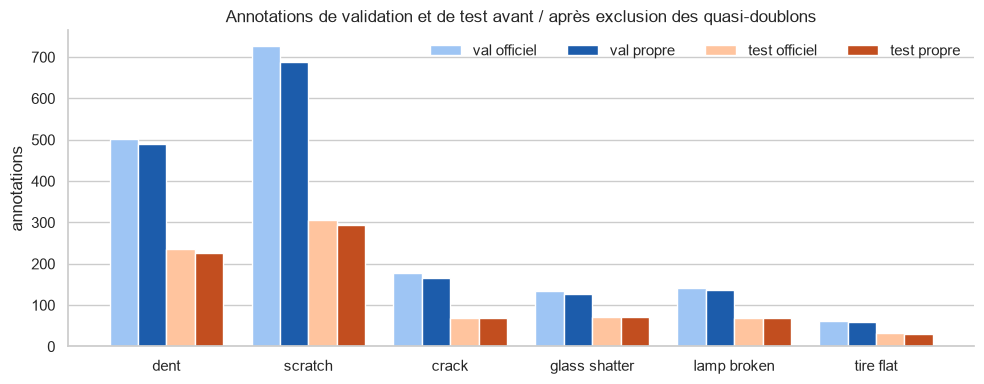

In [15]:
before = pd.crosstab(annotations["category_name"], annotations["split"]).loc[CLASS_ORDER, list(SPLITS)]
after = pd.crosstab(ann_ok.loc[ann_ok["image_eval_keep"], "category_name"],
                    ann_ok.loc[ann_ok["image_eval_keep"], "split"]).reindex(index=CLASS_ORDER, columns=list(SPLITS), fill_value=0)
table = pd.concat({"avant": before, "après": after}, axis=1).swaplevel(axis=1)[list(SPLITS)]
display(table)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(CLASS_ORDER)); w = 0.2
for k, split in enumerate(["val", "test"]):
    ax.bar(x + (2 * k - 1) * w - w / 2, before[split], w, color=["#9ec5f4", "#ffc49e"][k], label=f"{split} officiel")
    ax.bar(x + (2 * k - 1) * w + w / 2, after[split], w, color=["#1c5cab", "#c24e1f"][k], label=f"{split} propre")
ax.set_xticks(x, CLASS_ORDER); ax.set_ylabel("annotations"); ax.legend(frameon=False, ncol=4)
ax.set_title("Annotations de validation et de test avant / après exclusion des quasi-doublons")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

**Interprétation.** Le train est **inchangé** (2816 images, 6211 annotations). L'exclusion concerne surtout la validation (≈ 4 % des images) et un peu le test (≈ 3 %).
Les proportions de classes sont pratiquement préservées : les classes rares (*tire flat*, *glass shatter*) restent représentées, et le test propre garde des effectifs suffisants pour être interprété.
Les exclusions touchent surtout *scratch* (40 annotations retirées en validation), la classe où les photos retouchées sont les plus fréquentes.

## 10. Sélection des colonnes utiles pour la classification

CarDD a été conçu pour la **détection** et la **segmentation**. Pour une **classification de zones**, seule une partie des informations est utile :
- la **bbox** sert à **découper** la zone dans la photo (c'est ce qui transforme un dataset de détection en dataset de classification) ; sa taille n'est **pas** une variable du modèle, car dans l'application c'est l'utilisateur qui recadre ;
- la **catégorie** est l'étiquette *y* ;
- les identifiants et dimensions servent à retrouver le fichier et à rester dans les limites de l'image.

Les fichiers originaux ne sont pas modifiés : on construit simplement une nouvelle table sans les champs inutiles.

In [16]:
from src.data.coco_loader import load_image_info
print("Preuve que ces champs sont constants :", cl.constant_fields(annotations, images))
pd.DataFrame(list(cl.DROPPED_FIELDS.items()), columns=["champ non repris", "raison"])

Preuve que ces champs sont constants : {'annotations.iscrowd': [0], 'annotations.attributes.occluded': ['False'], 'images.license': [0]}


,champ non repris,raison
0,annotations.segmentation,contour polygonal pour la segmentation ; l'application n...
1,annotations.area,"surface du polygone, dérivée de la segmentation"
2,annotations.iscrowd,valeur constante (toujours 0)
3,annotations.attributes.occluded,valeur constante (toujours False)
4,images.license,valeur constante (toujours 0)
5,info / licenses,"métadonnées d'auteur (à citer dans le rapport, inutiles ..."
6,"xlsx: id, file_name, width, height",redondants avec les JSON (vérifié identiques)
7,xlsx: file_size (KB),sans lien avec le type de dommage
8,"xlsx: #instances, #categories",recalculables depuis les JSON


In [17]:
regions = cl.build_region_table(images, annotations, ann_dec)
metadata = cl.build_image_metadata(load_image_info())
print(f"Table des régions : {regions.shape[0]} lignes × {regions.shape[1]} colonnes -> {list(regions.columns)}")
print(f"Métadonnées (analyse d'erreurs uniquement) : {metadata.shape[0]} lignes -> {list(metadata.columns)}")
regions.head()

Table des régions : 8740 lignes × 15 colonnes -> ['split', 'annotation_id', 'image_id', 'file_name', 'width', 'height', 'bbox_x', 'bbox_y', 'bbox_w', 'bbox_h', 'category_id', 'category_name', 'keep', 'image_eval_keep', 'flags']
Métadonnées (analyse d'erreurs uniquement) : 4000 lignes -> ['image_id', 'file_name', 'shooting_angle', 'complete_or_partial', 'color']


,split,annotation_id,image_id,file_name,width,height,bbox_x,bbox_y,bbox_w,bbox_h,category_id,category_name,keep,image_eval_keep,flags
0,train,1,1,000001.jpg,1000,750,167.04,40.21,202.79,131.34,2,scratch,True,True,
1,train,2,1,000001.jpg,1000,750,160.66,112.45,684.19,551.02,6,tire flat,True,True,
2,train,3,2,000002.jpg,1000,667,476.73,241.02,397.20,346.68,6,tire flat,True,True,
3,train,4,3,000003.jpg,1000,667,354.29,0.00,645.71,521.12,6,tire flat,True,True,
4,train,5,4,000004.jpg,1000,667,129.29,0.00,718.62,649.69,6,tire flat,True,True,


**Interprétation.** `iscrowd`, `occluded` et `license` n'ont qu'**une seule valeur** dans tout le dataset : ils ne peuvent rien apprendre au modèle.
`segmentation` et `area` décrivent le contour exact, utile à un modèle de segmentation mais **indisponible dans l'application** (l'utilisateur trace un rectangle).
Les métadonnées `shooting_angle`, `complete_or_partial` et `color` sont gardées **dans un fichier séparé** : elles ne seront jamais des variables d'entrée,
mais permettront d'analyser les erreurs en phase 5.

## 11. Export des résultats

In [18]:
issues_all = pd.concat([ids, unknown, orphans, files, corrupt, ann_issues], ignore_index=True)
issues_all.to_csv(REPORT_DIR / "issues.csv", index=False, encoding="utf-8")
pairs.drop(columns=["i", "j"]).query("inliers >= 15").to_csv(REPORT_DIR / "duplicate_pairs.csv", index=False, encoding="utf-8")
groups.to_csv(REPORT_DIR / "duplicate_groups.csv", index=False, encoding="utf-8")
image_dec.to_csv(REPORT_DIR / "image_decisions.csv", index=False, encoding="utf-8")
ann_dec.to_csv(REPORT_DIR / "annotation_decisions.csv", index=False, encoding="utf-8")
summary.to_csv(REPORT_DIR / "cleaning_summary.csv", encoding="utf-8")
regions.to_csv(REPORT_DIR / "regions.csv", index=False, encoding="utf-8")
metadata.to_csv(REPORT_DIR / "image_metadata.csv", index=False, encoding="utf-8")
for p in sorted(REPORT_DIR.iterdir()):
    print(f"{p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size / 1024:.0f} Ko)")

reports\cleaning\annotation_decisions.csv  (297 Ko)
reports\cleaning\cleaning_summary.csv  (0 Ko)
reports\cleaning\duplicate_groups.csv  (6 Ko)
reports\cleaning\duplicate_pairs.csv  (14 Ko)
reports\cleaning\image_decisions.csv  (116 Ko)
reports\cleaning\image_metadata.csv  (137 Ko)
reports\cleaning\issues.csv  (7 Ko)
reports\cleaning\regions.csv  (710 Ko)


## 12. Synthèse

> Un rapport dédié aux doublons (SHA-256 + pHash + ORB) est généré par `python -m src.data.duplicate_report` dans `reports/duplicates/`.

- Le dataset CarDD est **structurellement propre** : aucun champ manquant, aucun id incohérent, aucune catégorie inconnue, aucun orphelin, aucun fichier manquant ou corrompu, aucune bbox invalide, aucun doublon exact.
- Les seules annotations signalées sont **96 bbox très fines**, conservées (vraies fissures) et à traiter par une marge de contexte en phase 3.
- Le vrai problème trouvé est la présence de **quasi-doublons** (photos recolorées, retournées, éclaircies, ou même scène re-photographiée), dont une partie **traverse les splits**.
  Ils sont détectés par ORB + RANSAC et neutralisés **sans modifier les splits officiels**, grâce à une évaluation « propre ».
- **Limites** : le seuil de 25 inliers laisse quelques faux positifs (exclusions inutiles, sans danger) et pourrait manquer des copies très fortement recadrées ou déformées.

**Pour la phase 3** : on partira de `reports/cleaning/regions.csv` (colonnes utiles uniquement) ; les régions avec `keep == True` seront extraites ; la validation et le test utiliseront `image_eval_keep` pour la version propre.